# Estudo Comparativo de Classificação Acústica Submarina — Dataset IARA
### Notebook 13: Complementaridade das entradas do SVM, oráculo e grau de consenso na classe LARGE

**Autor:** Evandro Rocha (UFRJ / COPPE / PEE)
**Data:** Outubro de 2026

---

## Resumo

A classe **`LARGE`** (embarcações de grande porte — mercantes, graneleiros, petroleiros, porta-contêineres —, comprimento $> 100\text{ m}$ segundo *Silva et al.*, IEEE Access 2025) é a de maior recall entre as classes de navio para os SVMs deste estudo. Completando os Notebooks 13 (`SMALL`) e 12 (`MEDIUM`), este notebook aplica a mesma análise de complementaridade das 4 entradas (MEL, LOFAR, HHT, DEMON) à classe `LARGE`.

A análise é feita por **instância arquivo × fold de teste** (2.140 instâncias de `LARGE`, 572 gravações únicas; em média cada arquivo aparece 3,75 vezes no teste ao longo das 10 dobras). Todos os números abaixo são recalculados das predições em disco por `notebooks/iara_results.py`.

### Principais resultados
1. **Recall isolado em `LARGE`:** SVM LOFAR (m=6000) 76,31%; SVM MEL (m=4000) 69,25%; SVM DEMON (m=4000) 65,79%; SVM HHT (m=4000) 64,72%. Atenção: SVM HHT (m=4000) e SVM DEMON (m=4000) são instáveis entre folds (SP global 52,31 ± 6,94% e 30,25 ± 21,66%).
2. **Oráculo (não realizável):** ao menos uma entrada acerta 1.944 instâncias (90,84%); todas erram em 196 (9,16%). Média por fold: **observado 90,84% vs. 99,08% esperado se os erros fossem independentes** — os erros são **positivamente correlacionados**, isto é, tendem a cair nos mesmos áudios. Para comparação, 4 preditores aleatórios dariam 68,36%.
3. **Consenso:** 859 instâncias (40,14%) são acertadas pelas 4 entradas; 246 (12,65% dos acertos do oráculo) dependem de uma única entrada.
4. **Voto real** entre as 4 entradas: recall `LARGE` 76,31 ± 6,19% vs. 76,31 ± 4,38% do SVM LOFAR (m=6000) (F-test 5×2cv $p=0,749$, não significativo); SP global 65,08 ± 3,36% vs. 63,83 ± 1,91% do SVM LOFAR (m=6000) ($p=0,538$, não significativo). A regra "≥2/4" (79,35%) conta empates como acerto e não é um voto realizável.
5. **Efeito reverso:** trocar cegamente o SVM LOFAR (m=6000) por outra entrada — MEL: perde 256 e resgata 105 (saldo -151); HHT: perde 374 e resgata 126 (saldo -248); DEMON: perde 446 e resgata 221 (saldo -225).
6. **Destino dos erros:** MEL → `SMALL` (48,02%); LOFAR → `MEDIUM` (45,96%); HHT → `SMALL` (59,21%); DEMON → `SMALL` (54,37%). Os erros **coincidem com frequência**: MEL e LOFAR erram ambos em 402 instâncias, 269 delas para a mesma classe; $P(\text{LOFAR erra}\mid\text{MEL erra}) = 61,09\%$ contra $P(\text{LOFAR erra}) = 23,69\%$.

> Os números de HHT/DEMON desta versão diferem da versão anterior porque o SVM HHT/DEMON $m=4000$ não é reprodutível entre execuções (ver seção 2).

In [1]:
# 1. Configuração do ambiente e imports
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

sys.path.insert(0, os.path.abspath('.') if os.path.exists('iara_results.py') else os.path.abspath('notebooks'))
sys.path.insert(0, os.path.abspath('src'))  # módulos movidos para notebooks/src
sys.path.insert(0, os.path.abspath('notebooks/src'))

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 13,
                     'xtick.labelsize': 10, 'ytick.labelsize': 10, 'figure.titlesize': 15, 'figure.dpi': 150})

## 2. Metodologia e base de teste

- **Protocolo:** validação cruzada $5\times2$cv do artigo (10 partições, **estratificadas e isoladas por gravação de áudio (`ID`)**, `exclusive_header='ID'` em `src/iara/ml/experiment.py`). O isolamento é por gravação, **não** por navio: o mesmo navio pode aparecer em treino e teste.
- **Modelos (SVM Nyström RBF + SGD hinge, ElasticNet $\rho=0{,}15$, $C=2$):**
  - SVM MEL (m=4000) — `results/trainings/tests/svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0` (pipeline iara oficial);
  - SVM LOFAR (m=6000) — `results/trainings/tests/svm_nystroem_6000_lofar_elasticnet_l1r0.15` (pipeline iara oficial);
  - SVM HHT (m=4000) — `results/trainings/multirep/svm_nystroem_4000_hht_C2.0_elasticnet_l1r0.15_4c` (`scratch/analyze_small_errors_by_input.py`);
  - SVM DEMON (m=4000) — `results/trainings/multirep/svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_4c` (idem).
- **Predição por arquivo:** voto majoritário das janelas (`collections.Counter.most_common`, como o pipeline iara).
- **Unidade de análise:** **instância arquivo × fold de teste**. Há **2.140 instâncias** cuja classe real é `LARGE`, correspondentes a **572 gravações únicas**. As contagens abaixo são, portanto, de instâncias e não de áudios distintos.
- **Quantas vezes cada arquivo é testado:** cada fold tem 639 arquivos de teste (o pipeline reserva parte de cada metade para validação), e cada repetição do $5\times2$cv cobre em média 1.278 dos 1.706 arquivos. Assim, cada arquivo aparece no teste em média **3,75 vezes** nas 10 dobras (3,74 em `LARGE`), e **não 5 vezes**; distribuição do nº de aparições (todas as classes): 1×: 28, 2×: 144, 3×: 458, 4×: 680, 5×: 396 arquivos.

> **Aviso de reprodutibilidade (HHT/DEMON m=4000).** Os SVMs HHT e DEMON com $m=4000$ foram re-treinados em 20/10/2026 pelo `scratch/analyze_small_errors_by_input.py` (mesmo código e `random_state=42`). As novas predições **não reproduzem** as predições antigas usadas na versão anterior destes notebooks. Possíveis causas (não isoladas): diferença de versão do scikit-learn e paralelismo (`n_jobs=-1`) no Nyström + SGD com *early stopping*; o `config.json` destes dois experimentos **não registra** a versão do scikit-learn (no host está instalada a 1.9.0 e no contêiner `iara-dev` a 1.7.2). Trate o SVM HHT/DEMON $m=4000$ como de **baixa reprodutibilidade entre execuções/versões**. Por isso **todos** os números envolvendo HHT/DEMON (recalls, interseções, resgates exclusivos, oráculos) mudaram em relação à versão anterior. Os números de MEL e LOFAR (pipeline oficial) não mudaram. A última célula deste notebook mostra que os SVMs HHT/DEMON com outros $m$ (que levavam o mesmo rótulo "SVM HHT/DEMON" em outros notebooks) também diferem entre si.

In [2]:
# 2. Análise completa a partir das predições em disco
CLASS_IDX, CLASS_NAME = 2, 'LARGE'
import numpy as np
import pandas as pd
import iara_results as R

# Experimentos em disco (predições por janela, 10 folds do 5x2cv oficial)
EXPS = {
    "MEL":   "svm_nystroem_4000_log_melgram_elasticnet_l1r0.15_C2.0",       # tests/ (pipeline iara), m=4000
    "LOFAR": "svm_nystroem_6000_lofar_elasticnet_l1r0.15",                  # tests/ (pipeline iara), m=6000
    "HHT":   "svm_nystroem_4000_hht_C2.0_elasticnet_l1r0.15_4c",            # multirep/ (scratch), m=4000
    "DEMON": "svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_4c",          # multirep/ (scratch), m=4000
}
M_OF = {"MEL": 4000, "LOFAR": 6000, "HHT": 4000, "DEMON": 4000}
LBL = {k: f"SVM {k} (m={M_OF[k]})" for k in EXPS}
REPS = list(EXPS)
NAMES = [EXPS[k] for k in REPS]
CLS = ["SMALL", "MEDIUM", "LARGE", "BACKGROUND"]

# Uma linha por instância arquivo x fold de teste (arquivos presentes nos 4 experimentos)
_al = R.aligned(NAMES)
ALL = pd.concat([df.assign(fold=k) for k, df in _al.items()], ignore_index=True)
ALL = ALL.rename(columns={EXPS[k]: k for k in REPS})
D = ALL[ALL.Target == CLASS_IDX].reset_index(drop=True)
HIT = pd.DataFrame({k: D[k].values == CLASS_IDX for k in REPS})
NH = HIT.sum(axis=1).values

N_INST = len(D)                                   # instâncias arquivo x fold
N_REC = D.File.nunique()                          # gravações únicas
EVAL_PER_FILE_ALL = ALL.groupby("File").size().mean()   # avaliações de teste por arquivo (todas as classes)
EVAL_PER_FILE_CLS = D.groupby("File").size().mean()
N_FILES_TOTAL = ALL.File.nunique()
TEST_PER_FOLD = int(ALL.groupby("fold").size().iloc[0])
REP_COVER = float(np.mean([len(set(_al[2 * r].File) | set(_al[2 * r + 1].File)) for r in range(5)]))
APPEAR_DIST = ALL.groupby("File").size().value_counts().sort_index().to_dict()

# 1) Desempenho individual (contagens agregadas nas 10 dobras) e recall médio por fold
hits = {k: int(HIT[k].sum()) for k in REPS}
rec_pool = {k: 100 * hits[k] / N_INST for k in REPS}
rec_fold = {k: R.summary(EXPS[k])[f"R_{CLASS_NAME}"] for k in REPS}
sp_fold = {k: R.summary(EXPS[k])["SP"] for k in REPS}
rec_range = {k: (R.fold_metrics(EXPS[k])[f"R_{CLASS_NAME}"].min(), R.fold_metrics(EXPS[k])[f"R_{CLASS_NAME}"].max()) for k in REPS}
UNSTABLE = [k for k in REPS if sp_fold[k][1] > 5]   # desvio do SP > 5 p.p. entre folds: modelo instável/colapsado
ORDER = sorted(REPS, key=lambda k: (-hits[k], REPS.index(k)))
BEST = ORDER[0]
ORACLE_HITS = int((NH >= 1).sum())
df_hits = pd.DataFrame({
    "Modelo": [LBL[k] for k in REPS] + ["ORÁCULO (≥1 de 4; não realizável)"],
    "Acertos (instâncias)": [hits[k] for k in REPS] + [ORACLE_HITS],
    f"Recall {CLASS_NAME} agregado (%)": [round(rec_pool[k], 2) for k in REPS] + [round(100 * ORACLE_HITS / N_INST, 2)],
    f"Recall {CLASS_NAME} média±dp por fold (%)": [R.fmt(rec_fold[k]) for k in REPS] + ["—"],
    f"Recall {CLASS_NAME} mín–máx por fold (%)": [f"{rec_range[k][0]:.1f}–{rec_range[k][1]:.1f}" for k in REPS] + ["—"],
    "SP global 4c (%)": [R.fmt(sp_fold[k]) for k in REPS] + ["—"],
    "Experimento": NAMES + ["—"],
}).set_index("Modelo")

# 2) Oráculo observado vs. esperado com erros independentes (média por fold)
ORC = R.oracle_recall(NAMES).loc[CLASS_NAME]
ORC_OBS, ORC_EXP = float(ORC["oráculo observado"]), float(ORC["esperado c/ erros independentes"])
ORC_RANDOM = 100 * (1 - (3 / 4) ** 4)            # 4 preditores uniformes ao acaso em 4 classes

# 3) Grau de consenso
cons = {n: int((NH == n).sum()) for n in range(4, -1, -1)}
df_consensus = pd.DataFrame({
    "Nível de consenso": ["4 de 4 (unânime)", "3 de 4", "2 de 4", "1 de 4 (resgate exclusivo)", "0 de 4 (erro comum)"],
    "Instâncias": [cons[n] for n in range(4, -1, -1)],
    f"% do total {CLASS_NAME}": [round(100 * cons[n] / N_INST, 2) for n in range(4, -1, -1)],
    "% dentro do oráculo": [round(100 * cons[n] / ORACLE_HITS, 2) for n in range(4, 0, -1)] + [np.nan],
    "Gravações únicas": [D.File[NH == n].nunique() for n in range(4, -1, -1)],
}).set_index("Nível de consenso")

# 4) Regras de limiar (contagem de acertos) vs. VOTO REAL (pluralidade, empate sorteado)
ge = {k: int((NH >= k).sum()) for k in (4, 3, 2, 1)}
VOTE = R.majority_vote(NAMES)
VOTE_REC = (VOTE[f"R_{CLASS_NAME}"].mean(), VOTE[f"R_{CLASS_NAME}"].std(ddof=0))
VOTE_SP = (VOTE["SP"].mean(), VOTE["SP"].std(ddof=0))
BEST_SP = max(REPS, key=lambda k: sp_fold[k][0])
F_REC, P_REC = R.f_test_5x2(VOTE[f"R_{CLASS_NAME}"].values, R.fold_metrics(EXPS[BEST])[f"R_{CLASS_NAME}"].values)
F_SP, P_SP = R.f_test_5x2(VOTE["SP"].values, R.fold_metrics(EXPS[BEST_SP])["SP"].values)
# empates 2x2 com a classe correta entre as empatadas
P = D[REPS].values
n_tie_right = 0
for row in P:
    c = np.bincount(row, minlength=4)
    if c[CLASS_IDX] == c.max() and (c == c.max()).sum() > 1:
        n_tie_right += 1
df_vote = pd.DataFrame({
    "Regra": ["Unanimidade (4/4 acertam)", "≥3/4 acertam", "≥2/4 acertam (conta empates 2×2 como acerto)",
              "Oráculo ≥1/4 (não realizável)",
              "VOTO REAL (pluralidade, empate sorteado) — média por fold",
              f"Melhor modelo isolado: {LBL[BEST]} — média por fold"],
    f"Recall {CLASS_NAME} (%)": [round(100 * ge[4] / N_INST, 2), round(100 * ge[3] / N_INST, 2),
                                 round(100 * ge[2] / N_INST, 2), round(100 * ge[1] / N_INST, 2),
                                 R.fmt(VOTE_REC), R.fmt(rec_fold[BEST])],
}).set_index("Regra")

# 5) Resgates exclusivos (instâncias, gravações, gravações exclusivas em TODAS as suas aparições)
excl_rows = []
for k in REPS:
    m_ex = (NH == 1) & HIT[k].values
    files_ex = set(D.File[m_ex])
    always = sum(1 for f in files_ex if m_ex[D.File.values == f].all())
    excl_rows.append({"Modelo": LBL[k], "Instâncias": int(m_ex.sum()),
                      f"% do total {CLASS_NAME}": round(100 * m_ex.sum() / N_INST, 2),
                      "Gravações únicas": len(files_ex),
                      "Gravações exclusivas em todas as aparições": always})
df_exclusive = pd.DataFrame(excl_rows).set_index("Modelo").sort_values("Instâncias")
EXCL_CHAMP = df_exclusive["Instâncias"].idxmax()

# 6) Efeito reverso: trocar cegamente o melhor modelo isolado por outro
rev_rows = []
for k in REPS:
    if k == BEST:
        continue
    keep = int((HIT[BEST] & HIT[k]).sum()); lose = int((HIT[BEST] & ~HIT[k]).sum())
    resc = int((~HIT[BEST] & HIT[k]).sum())
    rev_rows.append({"Troca": f"{BEST} → {k}", "Mantém acertos": keep, "Perde acertos (efeito reverso)": lose,
                     "% perda": round(100 * lose / hits[BEST], 2), "Resgata erros": resc,
                     "% resgate": round(100 * resc / (N_INST - hits[BEST]), 2), "Saldo líquido": resc - lose})
df_reverse = pd.DataFrame(rev_rows).set_index("Troca")

# 7) Padrão de confusão: para onde vão os erros
conf_rows = []
for k in REPS:
    err = D[k][D[k] != CLASS_IDX]
    row = {"Modelo": f"{LBL[k]} ({len(err)} erros)"}
    for c in range(4):
        if c != CLASS_IDX:
            row[f"→ {CLS[c]} (%)"] = round(100 * (err == c).mean(), 2)
    conf_rows.append(row)
df_confusion = pd.DataFrame(conf_rows).set_index("Modelo")

# 8) Correlação dos erros entre pares: P(B erra | A erra) vs. P(B erra), e erro para a MESMA classe
pair_rows = []
for i, a in enumerate(REPS):
    for b in REPS[i + 1:]:
        ea, eb = ~HIT[a].values, ~HIT[b].values
        both = ea & eb
        same = int((both & (D[a].values == D[b].values)).sum())
        pair_rows.append({"Par": f"{a} × {b}", "P(B erra)": round(100 * eb.mean(), 2),
                          "P(B erra | A erra)": round(100 * eb[ea].mean(), 2),
                          "Ambos erram": int(both.sum()),
                          "Ambos erram p/ a mesma classe": same,
                          "% mesma classe": round(100 * same / max(both.sum(), 1), 2)})
df_pairs = pd.DataFrame(pair_rows).set_index("Par")

print(f'{N_INST} instâncias arquivo×fold de {CLASS_NAME}; {N_REC} gravações únicas; '
      f'{EVAL_PER_FILE_ALL:.2f} avaliações de teste por arquivo (todas as classes)')
display(df_hits)

2140 instâncias arquivo×fold de LARGE; 572 gravações únicas; 3.75 avaliações de teste por arquivo (todas as classes)


,Acertos (instâncias),Recall LARGE agregado (%),Recall LARGE média±dp por fold (%),Recall LARGE mín–máx por fold (%),SP global 4c (%),Experimento
Modelo,,,,,,
SVM MEL (m=4000),1482,69.25,69.25 ± 2.78,64.0–72.0,63.78 ± 1.14,svm_nystroem_4000_log_melgram_elasticnet_l1r0....
SVM LOFAR (m=6000),1633,76.31,76.31 ± 4.38,68.2–84.6,63.83 ± 1.91,svm_nystroem_6000_lofar_elasticnet_l1r0.15
SVM HHT (m=4000),1385,64.72,64.72 ± 14.46,41.1–92.5,52.31 ± 6.94,svm_nystroem_4000_hht_C2.0_elasticnet_l1r0.15_4c
SVM DEMON (m=4000),1408,65.79,65.79 ± 27.38,7.9–96.3,30.25 ± 21.66,svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.1...
ORÁCULO (≥1 de 4; não realizável),1944,90.84,—,—,—,—


## 3. Oráculo: recall individual vs. união dos acertos

Recall agregado em `LARGE` (acertos / 2.140 instâncias; como todo fold tem o mesmo número de arquivos de `LARGE`, coincide com a média por fold): SVM LOFAR (m=6000) 76,31%; SVM MEL (m=4000) 69,25%; SVM DEMON (m=4000) 65,79%; SVM HHT (m=4000) 64,72%. O melhor modelo isolado é o **SVM LOFAR (m=6000)**.

> **Modelos instáveis.** SVM HHT (m=4000): SP global 52,31 ± 6,94%, recall `LARGE` entre 41,1% e 92,5% conforme o fold; SVM DEMON (m=4000): SP global 30,25 ± 21,66%, recall `LARGE` entre 7,9% e 96,3% conforme o fold. O desvio entre folds é muito maior que o dos SVMs MEL/LOFAR (SP 63,78 ± 1,14% e 63,83 ± 1,91%): em alguns folds o modelo colapsa para poucas classes. Recalls agregados desses modelos (e as interseções que os envolvem) misturam folds colapsados e não colapsados.


O **oráculo** (acerta se ao menos uma das 4 entradas acertar) cobre **1.944 instâncias (90,84%)**; o erro comum (todas erram) é de **196 instâncias (9,16%)**.

**Cuidados de interpretação:**
- O oráculo **não é um sistema realizável**: ele usa o rótulo verdadeiro para escolher a entrada. A união de preditores fracos cresce mesmo sem informação — 4 preditores uniformemente aleatórios em 4 classes já dariam recall esperado de $1-(3/4)^4 = 68,36\%$.
- A referência correta é o **esperado se os erros fossem independentes**, $1-\prod_i(1-r_i)$. Média por fold: **oráculo observado 90,84% vs. esperado sob independência 99,08%**. O observado fica **abaixo** do esperado: os erros das 4 entradas são **positivamente correlacionados** (tendem a cair nos mesmos áudios), o que é o oposto de complementaridade forte.

,oráculo observado,esperado c/ erros independentes
SMALL,81.179775,88.510510
MEDIUM,82.214765,95.523757
LARGE,90.841121,99.080874
BACKGROUND,95.102041,99.470586


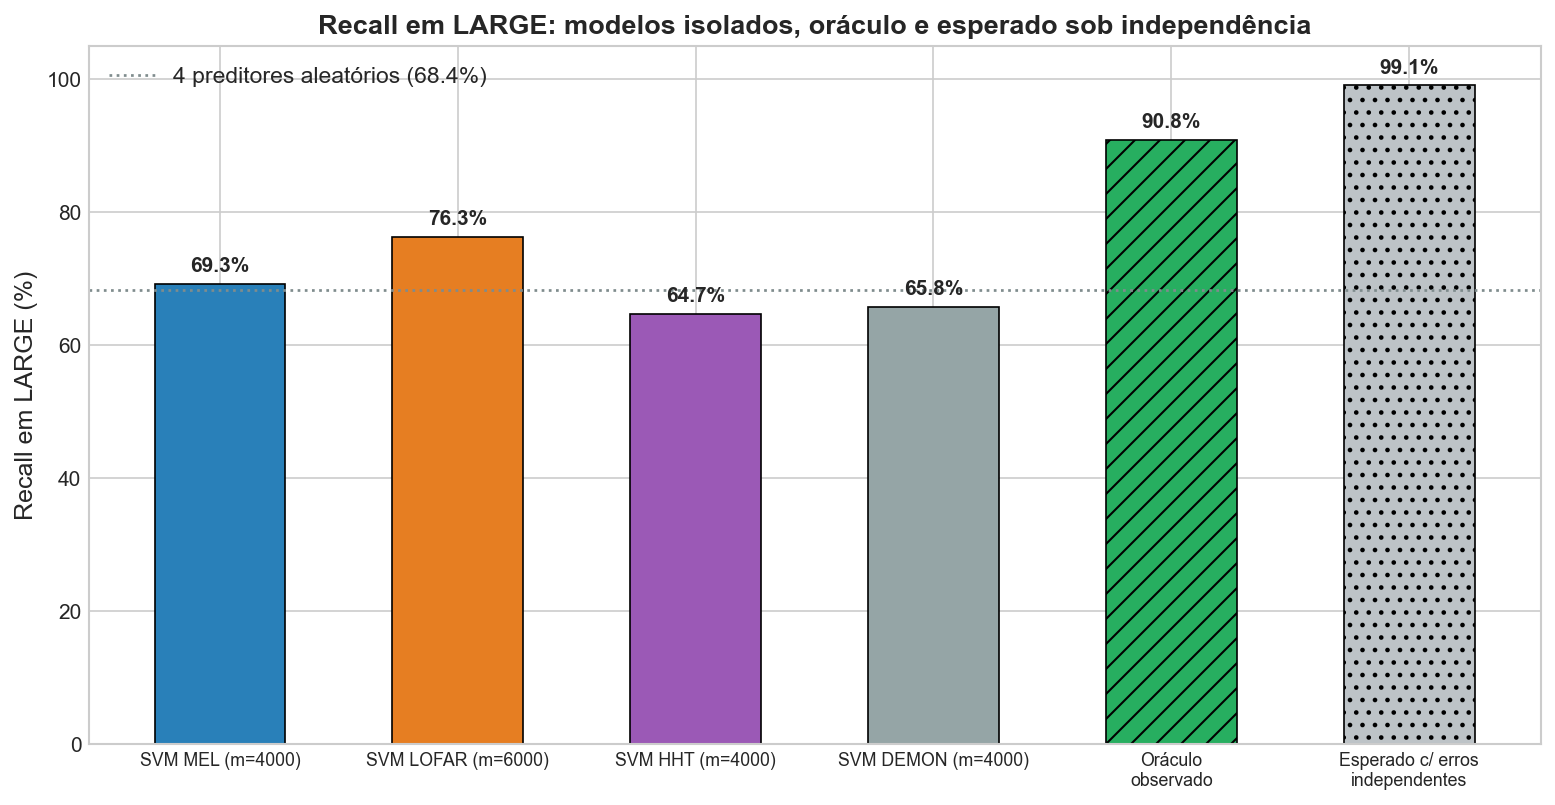

In [3]:
# 3. Oráculo observado vs. esperado com erros independentes (média por fold) + gráfico
display(R.oracle_recall(NAMES))
fig, ax = plt.subplots(figsize=(10.5, 5.5))
labels = [LBL[k] for k in REPS] + ['Oráculo\nobservado', 'Esperado c/ erros\nindependentes']
vals = [rec_pool[k] for k in REPS] + [100 * ORACLE_HITS / N_INST, ORC_EXP]
colors = ['#2980b9', '#e67e22', '#9b59b6', '#95a5a6', '#27ae60', '#bdc3c7']
bars = ax.bar(labels, vals, color=colors, width=0.55, edgecolor='black', linewidth=0.8)
bars[-2].set_hatch('//'); bars[-1].set_hatch('..')
ax.axhline(ORC_RANDOM, color='#7f8c8d', ls=':', lw=1.3, label=f'4 preditores aleatórios ({ORC_RANDOM:.1f}%)')
for b in bars:
    ax.annotate(f'{b.get_height():.1f}%', xy=(b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 4),
                textcoords='offset points', ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title(f'Recall em {CLASS_NAME}: modelos isolados, oráculo e esperado sob independência', fontweight='bold')
ax.set_ylabel(f'Recall em {CLASS_NAME} (%)'); ax.set_ylim(0, 105); ax.legend(loc='upper left')
plt.xticks(fontsize=8.5); plt.tight_layout(); plt.show()

## 4. Grau de consenso, regras de votação e voto real

### 4.1 Pirâmide de consenso (instâncias arquivo × fold)
- **4 de 4 corretas:** 859 (40,14%);
- **3 de 4:** 548 (25,61%);
- **2 de 4:** 291 (13,60%);
- **1 de 4 (resgate exclusivo):** 246 (11,50%; 12,65% dos acertos do oráculo);
- **0 de 4 (erro comum):** 196 (9,16%).

### 4.2 Regras de limiar vs. voto real
- Unanimidade (4/4): 40,14%; ≥3/4: 65,75%; ≥2/4: 79,35%; oráculo ≥1/4: 90,84%.
- A regra "≥2/4" (`c4 + c3 + c2`) **não é uma votação**: ela conta como acerto os empates $2\times2$, que um voto real só acerta por sorteio. Há **146 instâncias** em que a classe correta está empatada com outra no topo da votação.
- **Voto real** (pluralidade entre as 4 entradas, empate sorteado; `R.majority_vote`), média por fold: recall `LARGE` = **76,31 ± 6,19%**, contra **76,31 ± 4,38%** do melhor modelo isolado, SVM LOFAR (m=6000). F-test 5×2cv sobre o recall `LARGE` por fold: $F=0,63$, $p=0,749$ — diferença **não significativa** (equivalentes dentro do desvio).
- Em **SP global** (4 classes), o voto real obtém **65,08 ± 3,36%**, contra **63,83 ± 1,91%** do melhor SVM isolado em SP, SVM LOFAR (m=6000); F-test 5×2cv: $F=0,99$, $p=0,538$ — não significativo.

,Instâncias,% do total LARGE,% dentro do oráculo,Gravações únicas
Nível de consenso,,,,
4 de 4 (unânime),859,40.14,44.19,339
3 de 4,548,25.61,28.19,330
2 de 4,291,13.60,14.97,187
1 de 4 (resgate exclusivo),246,11.50,12.65,147
0 de 4 (erro comum),196,9.16,NaN,98


,Recall LARGE (%)
Regra,
Unanimidade (4/4 acertam),40.14
≥3/4 acertam,65.75
≥2/4 acertam (conta empates 2×2 como acerto),79.35
Oráculo ≥1/4 (não realizável),90.84
"VOTO REAL (pluralidade, empate sorteado) — média por fold",76.31 ± 6.19
Melhor modelo isolado: SVM LOFAR (m=6000) — média por fold,76.31 ± 4.38


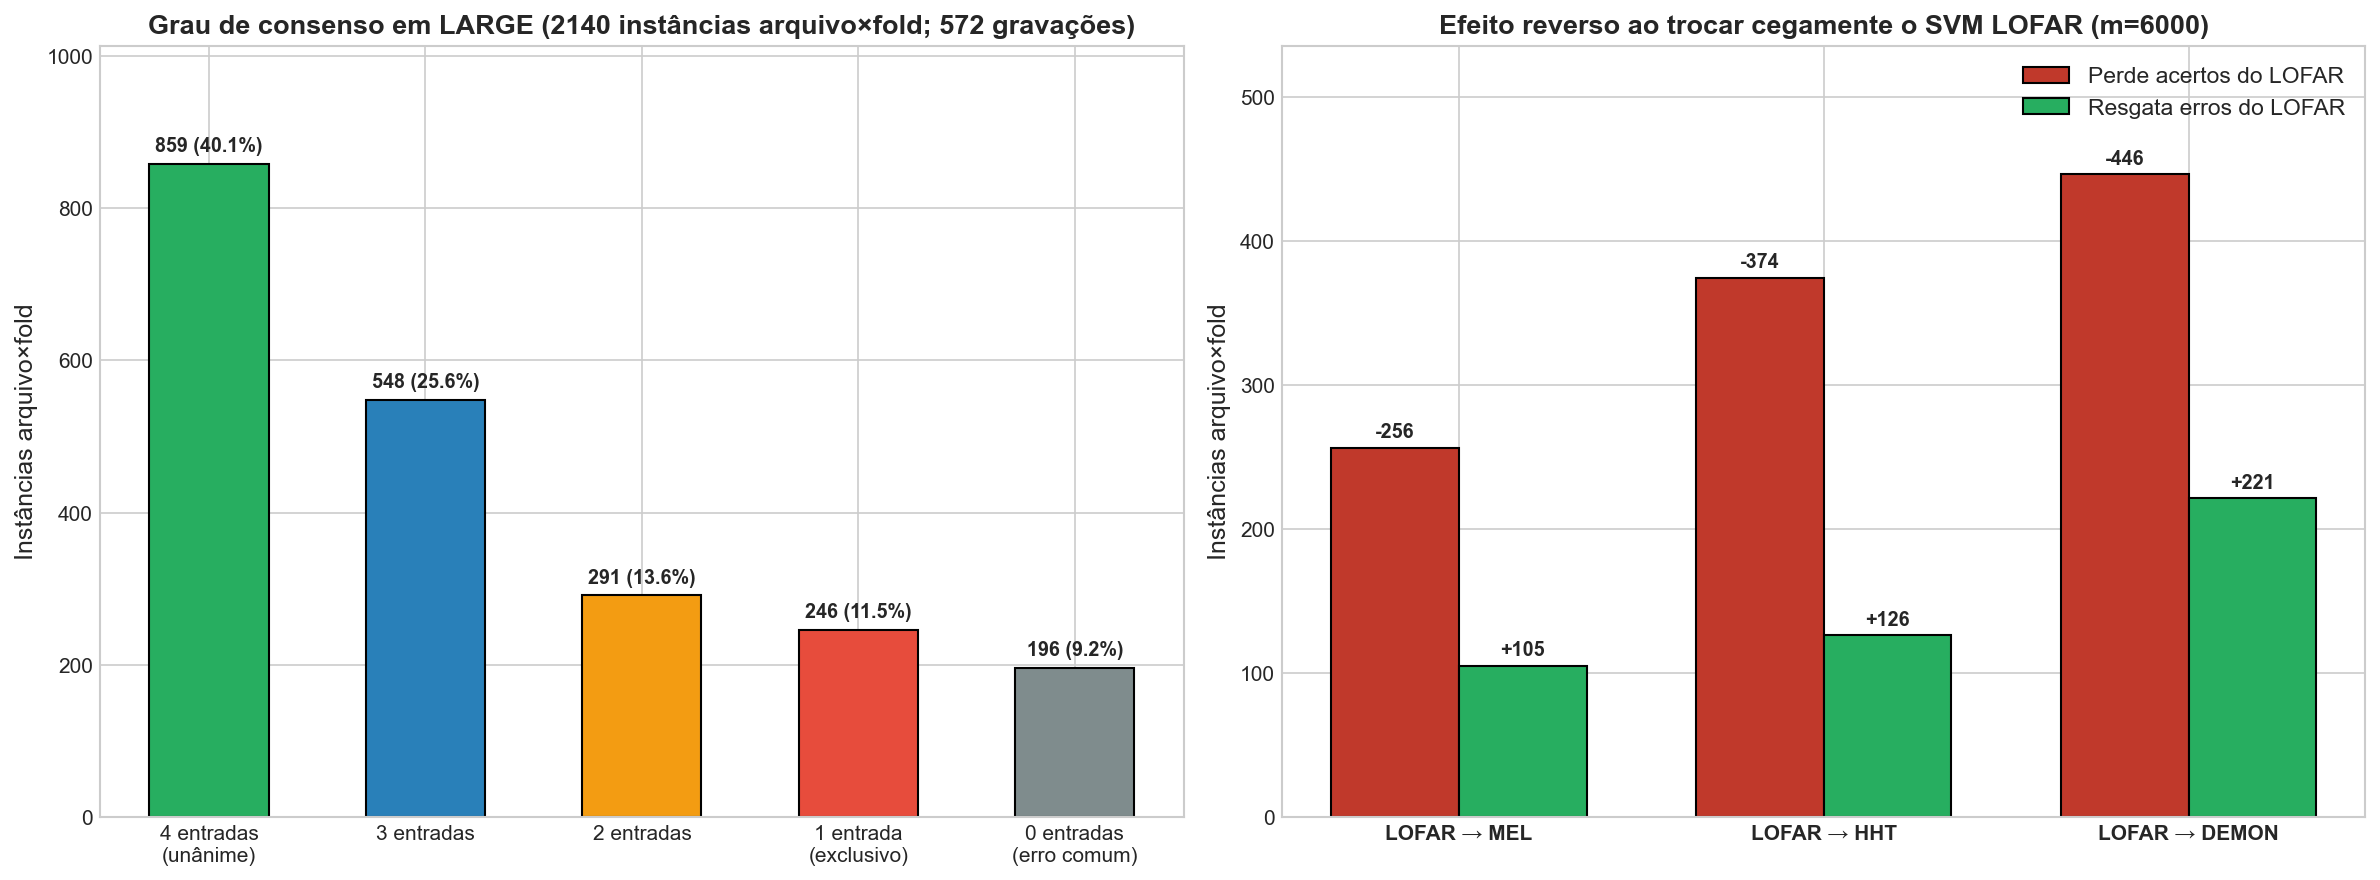

,Mantém acertos,Perde acertos (efeito reverso),% perda,Resgata erros,% resgate,Saldo líquido
Troca,,,,,,
LOFAR → MEL,1377,256,15.68,105,20.71,-151
LOFAR → HHT,1259,374,22.90,126,24.85,-248
LOFAR → DEMON,1187,446,27.31,221,43.59,-225


In [4]:
# 4. Tabelas de consenso e de votação + gráfico
display(df_consensus)
display(df_vote)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
labels_cons = ['4 entradas\n(unânime)', '3 entradas', '2 entradas', '1 entrada\n(exclusivo)', '0 entradas\n(erro comum)']
counts = df_consensus['Instâncias'].values
pcts = df_consensus[f'% do total {CLASS_NAME}'].values
b1 = ax1.bar(labels_cons, counts, color=['#27ae60', '#2980b9', '#f39c12', '#e74c3c', '#7f8c8d'], edgecolor='black', width=0.55)
for b, p in zip(b1, pcts):
    ax1.annotate(f'{int(b.get_height())} ({p:.1f}%)', xy=(b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 4),
                 textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')
ax1.set_title(f'Grau de consenso em {CLASS_NAME} ({N_INST} instâncias arquivo×fold; {N_REC} gravações)', fontweight='bold')
ax1.set_ylabel('Instâncias arquivo×fold'); ax1.set_ylim(0, counts.max() * 1.18)

dest = list(df_reverse.index)
r1 = ax2.bar(np.arange(len(dest)) - 0.175, df_reverse['Perde acertos (efeito reverso)'], 0.35, color='#c0392b', edgecolor='black', label=f'Perde acertos do {BEST}')
r2 = ax2.bar(np.arange(len(dest)) + 0.175, df_reverse['Resgata erros'], 0.35, color='#27ae60', edgecolor='black', label=f'Resgata erros do {BEST}')
for r, s in ((r1, '-'), (r2, '+')):
    for b in r:
        ax2.annotate(f'{s}{int(b.get_height())}', xy=(b.get_x() + b.get_width() / 2, b.get_height()), xytext=(0, 3),
                     textcoords='offset points', ha='center', va='bottom', fontsize=9.5, fontweight='bold')
ax2.set_xticks(np.arange(len(dest))); ax2.set_xticklabels(dest, fontweight='bold')
ax2.set_title(f'Efeito reverso ao trocar cegamente o {LBL[BEST]}', fontweight='bold')
ax2.set_ylabel('Instâncias arquivo×fold'); ax2.legend(loc='upper right')
ax2.set_ylim(0, max(df_reverse['Perde acertos (efeito reverso)'].max(), df_reverse['Resgata erros'].max()) * 1.2)
plt.tight_layout(); plt.show()
display(df_reverse)

### 4.3 Efeito reverso (troca cega a partir do melhor modelo isolado, SVM LOFAR (m=6000), 1.633 acertos)
- **LOFAR → MEL:** mantém 1.377, perde 256 acertos (15,68%) e resgata 105 erros (20,71%); saldo **-151**.
- **LOFAR → HHT:** mantém 1.259, perde 374 acertos (22,90%) e resgata 126 erros (24,85%); saldo **-248**.
- **LOFAR → DEMON:** mantém 1.187, perde 446 acertos (27,31%) e resgata 221 erros (43,59%); saldo **-225**.

Nenhuma troca cega é vantajosa: qualquer seletor precisaria identificar, **sem o rótulo**, as instâncias em que o LOFAR erra — o que é exatamente o que o oráculo pressupõe.

## 5. Resgates exclusivos

Em **246 instâncias** exatamente uma das entradas acerta:
- **SVM DEMON (m=4000):** 122 instâncias (5,70%), 78 gravações únicas; gravações que são resgate exclusivo em **todas** as suas aparições no teste: **4**.
- **SVM LOFAR (m=6000):** 55 instâncias (2,57%), 42 gravações únicas; gravações que são resgate exclusivo em **todas** as suas aparições no teste: **1**.
- **SVM HHT (m=4000):** 38 instâncias (1,78%), 33 gravações únicas; gravações que são resgate exclusivo em **todas** as suas aparições no teste: **1**.
- **SVM MEL (m=4000):** 31 instâncias (1,45%), 23 gravações únicas; gravações que são resgate exclusivo em **todas** as suas aparições no teste: **0**.

As contagens são de instâncias arquivo × fold, não de áudios distintos. A mesma gravação pode ser resgate exclusivo em um fold e não em outro (os modelos são re-treinados a cada fold), por isso a última coluna é bem menor que a primeira. Como as predições HHT/DEMON m=4000 **não são reprodutíveis** entre execuções (ver aviso na seção 2), o ranking de "resgates exclusivos" entre HHT e DEMON não deve ser tomado como propriedade física das representações. Explicações físicas para resgates individuais (cavitação, rotação de eixo etc.) **não foram verificadas** nos áudios e são apenas hipóteses.

,Instâncias,% do total LARGE,Gravações únicas,Gravações exclusivas em todas as aparições
Modelo,,,,
SVM MEL (m=4000),31,1.45,23,0
SVM HHT (m=4000),38,1.78,33,1
SVM LOFAR (m=6000),55,2.57,42,1
SVM DEMON (m=4000),122,5.70,78,4


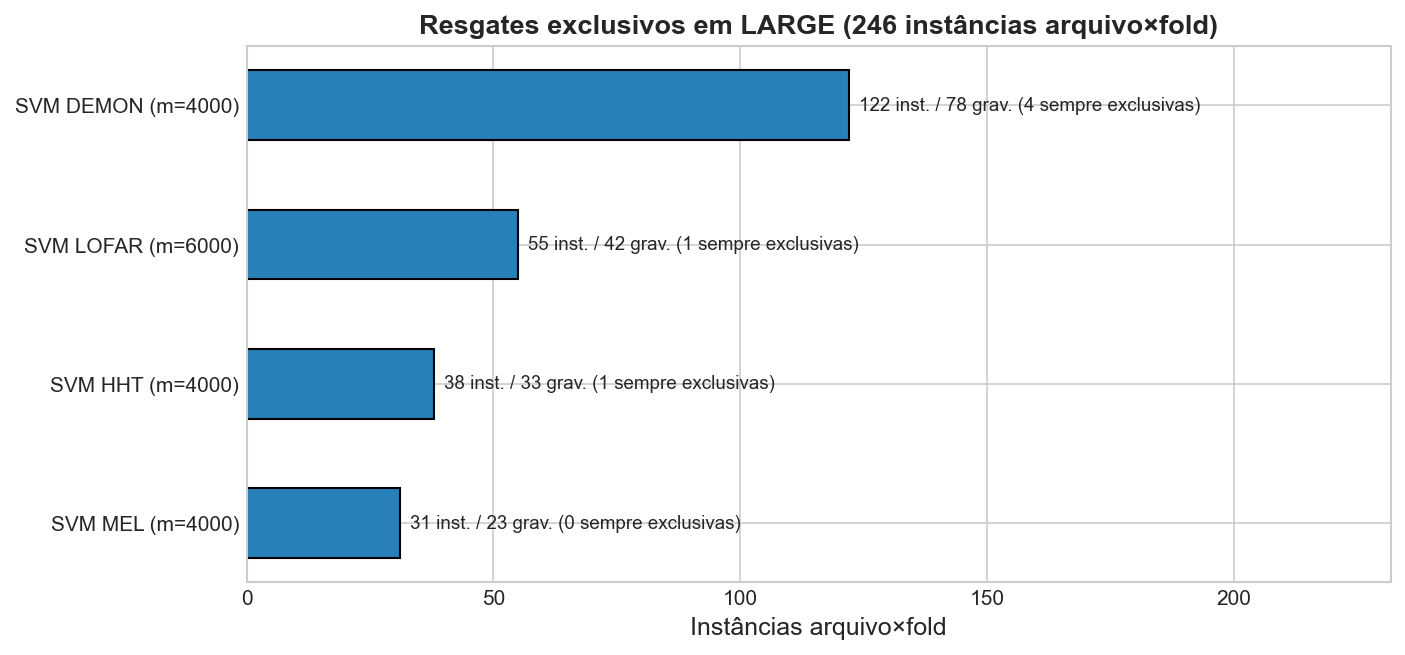

In [5]:
# 5. Resgates exclusivos
display(df_exclusive)
fig, ax = plt.subplots(figsize=(9.5, 4.5))
b = ax.barh(df_exclusive.index, df_exclusive['Instâncias'], color='#2980b9', height=0.5, edgecolor='black')
for bar, (_, r) in zip(b, df_exclusive.iterrows()):
    ax.annotate(f"{int(r['Instâncias'])} inst. / {int(r['Gravações únicas'])} grav. ({int(r['Gravações exclusivas em todas as aparições'])} sempre exclusivas)",
                xy=(bar.get_width(), bar.get_y() + bar.get_height() / 2), xytext=(5, 0), textcoords='offset points',
                ha='left', va='center', fontsize=9)
ax.set_title(f'Resgates exclusivos em {CLASS_NAME} ({int(df_exclusive["Instâncias"].sum())} instâncias arquivo×fold)', fontweight='bold')
ax.set_xlabel('Instâncias arquivo×fold'); ax.set_xlim(0, df_exclusive['Instâncias'].max() * 1.9)
plt.tight_layout(); plt.show()

## 6. Para onde vão os erros e correlação entre as entradas

| Modelo | → SMALL | → MEDIUM | → BACKGROUND |
| :--- | :---: | :---: | :---: |
| SVM MEL (m=4000) (658 erros) | 48,02% | 44,22% | 7,75% |
| SVM LOFAR (m=6000) (507 erros) | 38,86% | 45,96% | 15,19% |
| SVM HHT (m=4000) (755 erros) | 59,21% | 29,54% | 11,26% |
| SVM DEMON (m=4000) (732 erros) | 54,37% | 34,29% | 11,34% |

**Correlação dos erros entre pares de entradas** (instâncias de `LARGE`). Se os erros fossem independentes, $P(B\text{ erra}\mid A\text{ erra}) \approx P(B\text{ erra})$:

| Par (A × B) | P(B erra) | P(B erra \| A erra) | Ambos erram | Ambos erram para a mesma classe |
| :--- | :---: | :---: | :---: | :---: |
| MEL × LOFAR | 23,69% | 61,09% | 402 | 269 (66,92%) |
| MEL × HHT | 35,28% | 68,84% | 453 | 215 (47,46%) |
| MEL × DEMON | 34,21% | 51,37% | 338 | 135 (39,94%) |
| LOFAR × HHT | 35,28% | 75,15% | 381 | 197 (51,71%) |
| LOFAR × DEMON | 34,21% | 56,41% | 286 | 108 (37,76%) |
| HHT × DEMON | 34,21% | 45,70% | 345 | 147 (42,61%) |

Em todos os pares a probabilidade condicional é maior que a marginal: quando uma entrada erra, a outra tende a errar também, e frequentemente para a **mesma** classe. A afirmação de versões anteriores de que as entradas "nunca concordam no erro" é falsa.
As descrições físicas dos mecanismos de confusão (bandas, raias, IMFs, pás) são hipóteses não testadas neste notebook.

,→ SMALL (%),→ MEDIUM (%),→ BACKGROUND (%)
Modelo,,,
SVM MEL (m=4000) (658 erros),48.02,44.22,7.75
SVM LOFAR (m=6000) (507 erros),38.86,45.96,15.19
SVM HHT (m=4000) (755 erros),59.21,29.54,11.26
SVM DEMON (m=4000) (732 erros),54.37,34.29,11.34


,P(B erra),P(B erra | A erra),Ambos erram,Ambos erram p/ a mesma classe,% mesma classe
Par,,,,,
MEL × LOFAR,23.69,61.09,402,269,66.92
MEL × HHT,35.28,68.84,453,215,47.46
MEL × DEMON,34.21,51.37,338,135,39.94
LOFAR × HHT,35.28,75.15,381,197,51.71
LOFAR × DEMON,34.21,56.41,286,108,37.76
HHT × DEMON,34.21,45.70,345,147,42.61


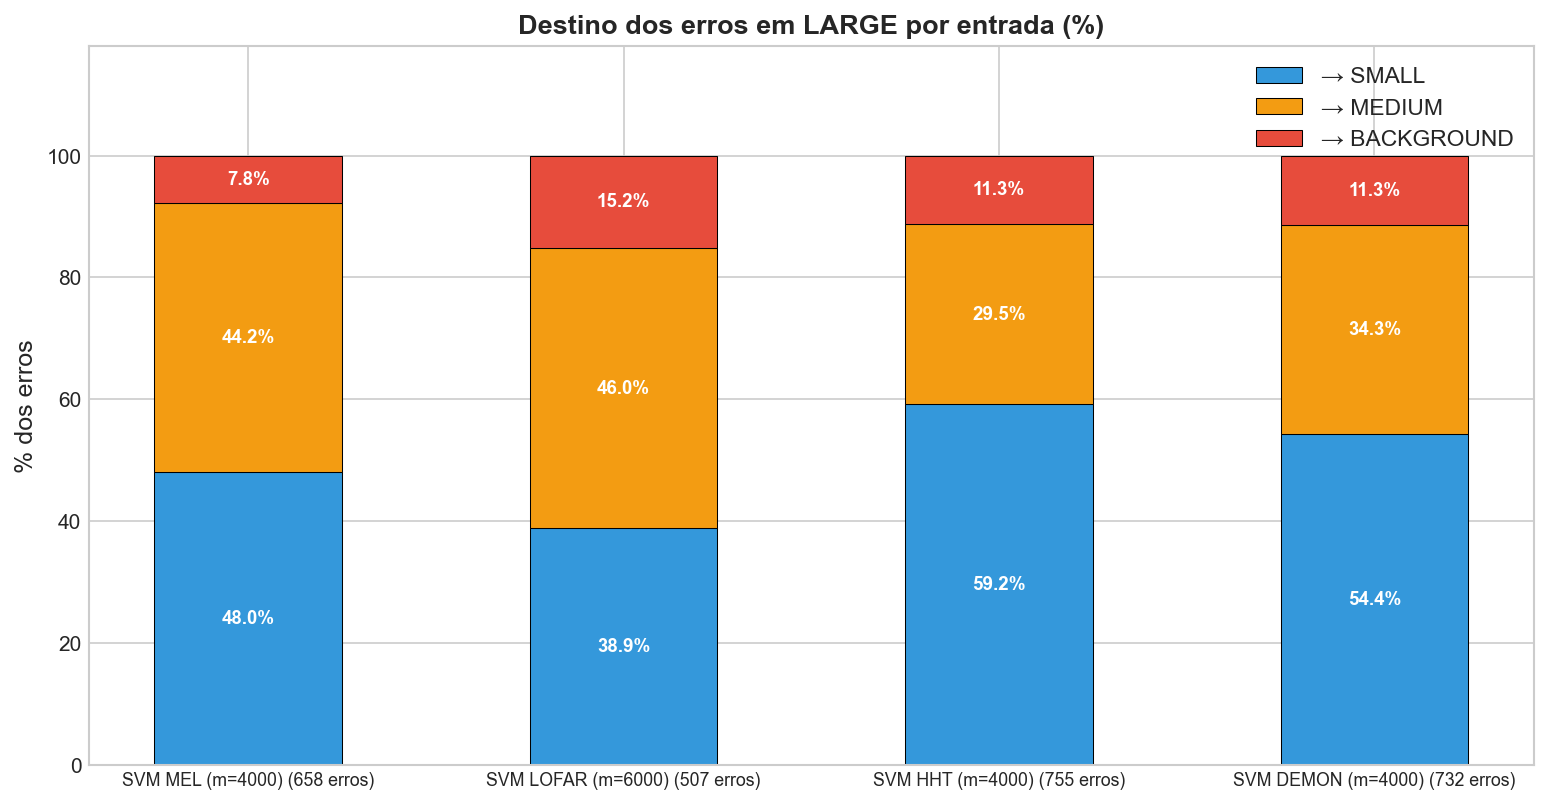

In [6]:
# 6. Padrão de confusão e correlação dos erros
display(df_confusion)
display(df_pairs)
fig, ax = plt.subplots(figsize=(10.5, 5.5))
bottom = np.zeros(len(df_confusion))
pal = ['#3498db', '#f39c12', '#e74c3c', '#95a5a6']
for i, c in enumerate(df_confusion.columns):
    v = df_confusion[c].values
    ax.bar(df_confusion.index, v, 0.5, bottom=bottom, label=c.replace(' (%)', ''), color=pal[i], edgecolor='black', linewidth=0.5)
    for j, (bb, vv) in enumerate(zip(bottom, v)):
        if vv > 4:
            ax.text(j, bb + vv / 2, f'{vv:.1f}%', ha='center', va='center', fontsize=9, fontweight='bold', color='white')
    bottom += v
ax.set_title(f'Destino dos erros em {CLASS_NAME} por entrada (%)', fontweight='bold')
ax.set_ylabel('% dos erros'); ax.set_ylim(0, 118); ax.legend(loc='upper right')
plt.xticks(fontsize=8.5); plt.tight_layout(); plt.show()

## 7. Variantes do SVM HHT/DEMON em disco

Há mais de um SVM HHT/DEMON no projeto, com o mesmo rótulo nominal em outros notebooks mas $m$ (número de componentes Nyström) e/ou `max_iter` diferentes. A tabela abaixo (SP e ACC = acurácia balanceada, média ± desvio sobre os 10 folds) mostra que eles **não são intercambiáveis**; neste notebook usa-se sempre o $m=4000$ indicado explicitamente.

In [7]:
# Os três SVMs HHT/DEMON existentes em disco (mesmo hiperparâmetro nominal, m diferente) — não são o mesmo modelo
VARIANTS = [
    ("SVM HHT m=2000 (exportação por arquivo, legado)", "svm_nystroem_2000_hht_C2.0_elasticnet_l1r0.15_4c"),
    ("SVM HHT m=4000 (usado neste notebook)", "svm_nystroem_4000_hht_C2.0_elasticnet_l1r0.15_4c"),
    ("SVM HHT m=6000", "svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15_4c"),
    ("SVM DEMON m=2000 (exportação por arquivo, legado)", "svm_nystroem_2000_demon_C2.0_elasticnet_l1r0.15_4c"),
    ("SVM DEMON m=4000 (usado neste notebook)", "svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_4c"),
    ("SVM DEMON m=4000, max_iter=1000", "svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.15_it1000_4c"),
]
display(R.table(VARIANTS))
import sklearn
print('scikit-learn neste kernel:', sklearn.__version__)

,SP,ACC,SMALL,MEDIUM,LARGE,BACKGROUND,Experimento
Modelo,,,,,,,
"SVM HHT m=2000 (exportação por arquivo, legado)",52.11 ± 5.43,54.56 ± 3.07,47.42,42.21,66.45,62.14,svm_nystroem_2000_hht_C2.0_elasticnet_l1r0.15_4c
SVM HHT m=4000 (usado neste notebook),52.31 ± 6.94,55.47 ± 2.98,45.90,49.13,64.72,62.14,svm_nystroem_4000_hht_C2.0_elasticnet_l1r0.15_4c
SVM HHT m=6000,51.18 ± 6.09,54.58 ± 2.36,43.54,49.46,61.64,63.67,svm_nystroem_6000_hht_C2.0_elasticnet_l1r0.15_4c
"SVM DEMON m=2000 (exportação por arquivo, legado)",43.75 ± 5.96,47.81 ± 5.00,40.39,46.04,55.23,49.59,svm_nystroem_2000_demon_C2.0_elasticnet_l1r0.1...
SVM DEMON m=4000 (usado neste notebook),30.25 ± 21.66,48.36 ± 7.89,28.43,45.97,65.79,53.27,svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.1...
"SVM DEMON m=4000, max_iter=1000",45.52 ± 5.75,53.11 ± 2.18,17.92,45.03,73.46,76.02,svm_nystroem_4000_demon_C2.0_elasticnet_l1r0.1...


scikit-learn neste kernel: 1.9.0


## 8. Implicações para um seletor de entrada

- O teto do oráculo **não** é uma meta atingível: ele pressupõe saber, sem o rótulo, quando cada entrada está certa. A referência honesta é o voto real e o melhor modelo isolado (SVM LOFAR (m=6000), recall `LARGE` 76,31 ± 4,38%).
- Como os erros são correlacionados e a troca cega sempre perde mais do que ganha, qualquer roteamento precisa de um sinal de confiança (margem do SVM, por exemplo) ajustado **fora** do conjunto de teste (folds internos), e o ganho só pode ser afirmado com o F-test 5×2cv.
- Ideias como *soft gating*/MoE ou *stacking* sobre os scores das 4 entradas são hipóteses de trabalho; este notebook não as avalia.

## 9. Síntese entre as classes de navio (NB 13, 14 e 15)

Todas as linhas abaixo são recalculadas agora para as três classes (instâncias arquivo × fold; média de 3,75 aparições de teste por arquivo, não 5).

| Métrica (instâncias arquivo × fold) | `SMALL` (NB 10) | `MEDIUM` (NB 12) | `LARGE` (NB 13) |
| :--- | :---: | :---: | :---: |
| Instâncias / gravações únicas | 1.780 / 476 | 1.490 / 397 | 2.140 / 572 |
| Melhor modelo isolado (recall) | MEL 50,73% | MEL 60,40% | LOFAR 76,31% |
| Oráculo observado (média por fold) | 81,18% | 82,21% | 90,84% |
| Esperado c/ erros independentes | 88,51% | 95,52% | 99,08% |
| Erro comum (0/4) | 18,82% (335) | 17,79% (265) | 9,16% (196) |
| Unanimidade (4/4) | 4,83% (86) | 26,98% (402) | 40,14% (859) |
| Resgates exclusivos (1/4) | 27,87% (496) | 18,93% (282) | 11,50% (246) |
| Maior nº de resgates exclusivos | HHT (195) | MEL (81) | DEMON (122) |
| Regra ≥2/4 (conta empates) | 53,31% | 63,29% | 79,35% |
| Voto real (média ± dp por fold) | 46,40 ± 12,01% | 59,26 ± 9,50% | 76,31 ± 6,19% |
| Melhor isolado (média ± dp por fold) | 50,73 ± 10,49% | 60,40 ± 11,59% | 76,31 ± 4,38% |
| F-test 5×2cv voto real vs. melhor isolado | p = 0,414 | p = 0,711 | p = 0,749 |

Média simples dos oráculos observados nas três classes de navio: 84,75% (esperado sob independência: 94,37%). Em todas as classes o oráculo observado fica abaixo do esperado com erros independentes; o oráculo não é um sistema realizável e não indica, por si só, que um roteador possa elevar o SP. Afirmações de que "o gargalo pode ser superado com roteamento dinâmico" ou de SP > 70% não são sustentadas por esta análise.

Os papéis físicos atribuídos a cada entrada em versões anteriores (LOFAR = raias de maquinário, DEMON = rotação de eixo a 1,3–2,0 Hz, HHT = transientes não lineares) são hipóteses: este notebook não mede frequências nem verifica os áudios.

## Conclusão

1. Uma parte grande dos erros em `LARGE` é **comum** às entradas: o oráculo observado (90,84%) fica abaixo do esperado sob independência (99,08%). Não se pode concluir que "a informação está presente no áudio, apenas dividida entre representações".
2. O consenso pleno cobre 40,14% das instâncias e 12,65% dos acertos do oráculo dependem de uma única entrada — mas esses resgates exclusivos são instáveis entre folds e, para HHT/DEMON, entre execuções do treino.
3. O voto real entre as 4 entradas não difere significativamente do melhor modelo isolado em recall `LARGE` (76,31 ± 6,19% vs. 76,31 ± 4,38%, p = 0,749) e, em SP global, obtém 65,08 ± 3,36% vs. 63,83 ± 1,91% (p = 0,538).